In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 1: Importações e Configurações
# ==============================================================================

# --- Importações Padrão ---
import pandas as pd
import numpy as np
import requests
import json
import os
import logging
from datetime import datetime
from io import BytesIO

# --- Importações Geoespaciais ---
import geopandas as gpd
from shapely.geometry import Point, LineString, MultiLineString
from shapely.ops import nearest_points
import pyproj

# --- Google Drive ---
from google.colab import drive

# ==============================================================================
# CONFIGURAÇÕES GERAIS
# ==============================================================================

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Definir pasta de trabalho no Drive
DRIVE_BASE_PATH = "/content/drive/MyDrive/Backup_ETL4_Recife"
os.makedirs(DRIVE_BASE_PATH, exist_ok=True)

# 3. Criar subpastas organizadas
DIR_RAW = os.path.join(DRIVE_BASE_PATH, "raw")
DIR_PROCESSED = os.path.join(DRIVE_BASE_PATH, "processed")
DIR_REPORTS = os.path.join(DIR_PROCESSED, "reports") # Ajuste para manter padrão ou DIR_REPORTS direto
DIR_REPORTS = os.path.join(DRIVE_BASE_PATH, "reports")

for directory in [DIR_RAW, DIR_PROCESSED, DIR_REPORTS]:
    os.makedirs(directory, exist_ok=True)

# 4. Configurar logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler(os.path.join(DIR_REPORTS, 'etl4_log.txt')),
        logging.StreamHandler()
    ]
)

# ==============================================================================
# CONFIGURAÇÕES DAS FONTES DE DADOS
# ==============================================================================

# S4 - Estações de Bikes
S4_URL = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=ciclovias-ciclofaixas-estacoes-de-aluguel-de-bikes-e-rotas"
S4_RESOURCE_ID = None

# S3 - Malha Cicloviária (usaremos apenas a permanente para o cálculo de 300m)
S3_URL = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=malha-cicloviaria-do-recife"

# S6 - Mapas de limites e divisões territoriais (bairros)
S6_URL = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=mapas-de-limites-e-divisoes-territoriais"

# ==============================================================================
# CONFIGURAÇÕES GEODÉSICAS
# ==============================================================================

# CRS de origem (geralmente WGS84 para CSVs de lat/lon e GeoJSONs)
CRS_ORIGEM = "EPSG:4326"

# CRS alvo (SIRGAS 2000 / UTM 25S - métrico para cálculos de distância em metros)
CRS_ALVO = "EPSG:31985"

# ==============================================================================
# CONSTANTES
# ==============================================================================

TARGET_YEAR = 2024
TIMEOUT_REQUEST = 60  # segundos
DISTANCIA_MAXIMA_M = 300  # Hipótese didática de proximidade

# ==============================================================================
# MENSAGEM INICIAL
# ==============================================================================

print("="*60)
print("✅ BLOCO 1 DO ETL 4 CARREGADO COM SUCESSO!")
print("="*60)
print(f"📁 Pasta de trabalho: {DRIVE_BASE_PATH}")
print(f"📍 CRS Origem: {CRS_ORIGEM}")
print(f"📍 CRS Alvo: {CRS_ALVO} (para cálculo de distância em metros)")
print(f"📏 Raio de proximidade analisado: {DISTANCIA_MAXIMA_M}m")
print("="*60)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ BLOCO 1 DO ETL 4 CARREGADO COM SUCESSO!
📁 Pasta de trabalho: /content/drive/MyDrive/Backup_ETL4_Recife
📍 CRS Origem: EPSG:4326
📍 CRS Alvo: EPSG:31985 (para cálculo de distância em metros)
📏 Raio de proximidade analisado: 300m


In [ ]:
# ==============================================================================
# BLOCO DE RESTAURAÇÃO DO ETL 4
# ==============================================================================

import os
import sqlite3
from google.colab import drive

# Montar o Google Drive
drive.mount('/content/drive')

# Configurar caminhos
DRIVE_BASE_PATH = "/content/drive/MyDrive/Backup_ETL4_Recife"
db_path = os.path.join(DRIVE_BASE_PATH, "estacoes_recife.db")

# Verificar se o banco já existe no Drive
if os.path.exists(db_path):
    print("="*60)
    print("✅ BANCO DE DADOS ENCONTRADO NO DRIVE!")
    print("="*60)
    print(f"📁 Local: {db_path}")
    print("\n🔄 Carregando dados diretamente do banco SQLite...")

    # Conectar ao banco
    con = sqlite3.connect(db_path)

    # Carregar tabelas
    fato_estacoes = pd.read_sql("SELECT * FROM fato_estacoes", con)
    dim_bairro = pd.read_sql("SELECT * FROM dim_bairro", con)
    dim_fonte = pd.read_sql("SELECT * FROM dim_fonte", con)

    con.close()

    print(f"✅ Dados restaurados com sucesso!")
    print(f"   - Fato estações: {len(fato_estacoes)} registros")
    print(f"   - Dimensão bairro: {len(dim_bairro)} registros")
    print(f"   - Dimensão fonte: {len(dim_fonte)} registros")
    print("\n💡 Você pode pular os blocos de extração, validação e processamento geoespacial.")
    print("   Prossega diretamente para as análises e indicadores.")
    print("="*60)

    # Flag para indicar que os dados foram restaurados
    DADOS_RESTAURADOS = True

else:
    print("="*60)
    print("⚠️ BANCO DE DADOS NÃO ENCONTRADO")
    print("="*60)
    print(f"📁 Local esperado: {db_path}")
    print("\n❗ Será necessário executar o pipeline completo:")
    print("   1. Download dos dados (S4, S3, S6)")
    print("   2. Limpeza, validação de coordenadas e criação do GeoDataFrame")
    print("   3. Interseção espacial com bairros e cálculo de proximidade (300m)")
    print("   4. Cálculo de indicadores e carga no banco")
    print("\n💡 Após a primeira execução, os dados serão salvos no Drive")
    print("   e você poderá restaurá-los nas próximas execuções.")
    print("="*60)

    # Flag para indicar que precisa executar o pipeline
    DADOS_RESTAURADOS = False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ BANCO DE DADOS ENCONTRADO NO DRIVE!
📁 Local: /content/drive/MyDrive/Backup_ETL4_Recife/estacoes_recife.db

🔄 Carregando dados diretamente do banco SQLite...
✅ Dados restaurados com sucesso!
   - Fato estações: 90 registros
   - Dimensão bairro: 94 registros
   - Dimensão fonte: 1 registros

💡 Você pode pular os blocos de extração, validação e processamento geoespacial.
   Prossega diretamente para as análises e indicadores.


In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 2: Descoberta dos Resource IDs via API CKAN
# ==============================================================================

import requests
import json

# ==============================================================================
# FUNÇÃO AUXILIAR: Consultar API CKAN
# ==============================================================================

def consultar_api_ckan(endpoint: str, params: dict = None) -> dict:
    """
    Consulta a API CKAN do Recife Dados com tratamento de erros.
    """
    url = f"https://dados.recife.pe.gov.br/api/3/action/{endpoint}"

    try:
        response = requests.get(url, params=params, timeout=TIMEOUT_REQUEST)
        response.raise_for_status()
        data = response.json()

        if not data.get("success"):
            raise ValueError(f"API retornou success=False: {data.get('error', 'Erro desconhecido')}")

        return data.get("result", {})

    except requests.exceptions.RequestException as e:
        logging.error(f"Erro na requisição à API: {e}")
        raise
    except json.JSONDecodeError as e:
        logging.error(f"Erro ao decodificar JSON da resposta: {e}")
        raise

# ==============================================================================
# CONSULTA S4: Estações de Bikes
# ==============================================================================

print("="*60)
print("🔍 CONSULTANDO PACOTE S4: Estações de Bikes")
print("="*60)

try:
    # Nota: O ID do pacote pode variar, usamos o slug comum do portal
    s4_metadata = consultar_api_ckan("package_show", {"id": "ciclovias-ciclofaixas-estacoes-de-aluguel-de-bikes-e-rotas"})

    logging.info(f"✅ Pacote S4 encontrado: {s4_metadata.get('title')}")

    s4_resources = s4_metadata.get("resources", [])
    logging.info(f"   Total de resources: {len(s4_resources)}")

    s4_estacoes_csv = None
    for resource in s4_resources:
        fmt = resource.get("format", "").upper()
        name = resource.get("name", "").lower()

        # Procurar por CSV que mencione estações
        if fmt == "CSV" and ("estacao" in name or "bike" in name or "bicicleta" in name):
            s4_estacoes_csv = resource
            logging.info(f"   📄 CSV de Estações encontrado: {resource.get('name')}")
            break

    # Fallback: se não achar pelo nome, pega o primeiro CSV
    if not s4_estacoes_csv:
        for resource in s4_resources:
            if resource.get("format", "").upper() == "CSV":
                s4_estacoes_csv = resource
                logging.info(f"   📄 CSV genérico encontrado: {resource.get('name')}")
                break

    if s4_estacoes_csv:
        S4_CSV_URL = s4_estacoes_csv.get("url")
        S4_CSV_RESOURCE_ID = s4_estacoes_csv.get("id")
        logging.info(f"   URL CSV Estações: {S4_CSV_URL}")
    else:
        logging.warning("⚠️ Nenhum CSV de estações encontrado no pacote S4!")
        S4_CSV_URL = None

except Exception as e:
    logging.error(f"❌ Erro ao consultar pacote S4: {e}")
    # Não vamos parar a execução aqui, pois podemos tentar outro ID ou o usuário pode inserir manualmente
    S4_CSV_URL = None

# ==============================================================================
# CONSULTA S3: Malha Cicloviária (Foco na Permanente para cálculo de 300m)
# ==============================================================================

print("\n" + "="*60)
print("🔍 CONSULTANDO PACOTE S3: Malha Cicloviária do Recife")
print("="*60)

try:
    s3_metadata = consultar_api_ckan("package_show", {"id": "malha-cicloviaria-do-recife"})
    logging.info(f"✅ Pacote S3 encontrado: {s3_metadata.get('title')}")

    s3_resources = s3_metadata.get("resources", [])

    s3_geojson = None
    for resource in s3_resources:
        fmt = resource.get("format", "").upper()
        name = resource.get("name", "").lower()
        if fmt == "GEOJSON" or "geojson" in name:
            s3_geojson = resource
            logging.info(f"   📍 GeoJSON encontrado: {resource.get('name')}")
            break

    if s3_geojson:
        S3_GEOJSON_URL = s3_geojson.get("url")
        logging.info(f"   URL GeoJSON Malha: {S3_GEOJSON_URL}")
    else:
        S3_GEOJSON_URL = None

except Exception as e:
    logging.error(f"❌ Erro ao consultar pacote S3: {e}")
    S3_GEOJSON_URL = None

# ==============================================================================
# CONSULTA S6: Mapas de Limites e Divisões Territoriais
# ==============================================================================

print("\n" + "="*60)
print("🔍 CONSULTANDO PACOTE S6: Mapas de Limites e Divisões Territoriais")
print("="*60)

try:
    s6_metadata = consultar_api_ckan("package_show", {"id": "mapas-de-limites-e-divisoes-territoriais"})
    logging.info(f"✅ Pacote S6 encontrado: {s6_metadata.get('title')}")

    s6_resources = s6_metadata.get("resources", [])

    s6_bairros_geojson = None
    for resource in s6_resources:
        fmt = resource.get("format", "").upper()
        name = resource.get("name", "").lower()
        if fmt == "GEOJSON" and "bairro" in name:
            s6_bairros_geojson = resource
            logging.info(f"   📍 GeoJSON de Bairros encontrado: {resource.get('name')}")
            break

    if s6_bairros_geojson:
        S6_BAIRROS_URL = s6_bairros_geojson.get("url")
        logging.info(f"   URL GeoJSON Bairros: {S6_BAIRROS_URL}")
    else:
        S6_BAIRROS_URL = None

except Exception as e:
    logging.error(f"❌ Erro ao consultar pacote S6: {e}")
    S6_BAIRROS_URL = None

# ==============================================================================
# RESUMO DOS RECURSOS ENCONTRADOS
# ==============================================================================

print("\n" + "="*60)
print("📋 RESUMO DOS RECURSOS ENCONTRADOS PARA ETL 4")
print("="*60)

print(f"\nS4 - Estações de Bikes:")
print(f"   CSV: {'✅' if S4_CSV_URL else '❌'} {S4_CSV_URL or 'Não encontrado'}")

print(f"\nS3 - Malha Cicloviária (Apoio):")
print(f"   GeoJSON: {'✅' if S3_GEOJSON_URL else '❌'} {S3_GEOJSON_URL or 'Não encontrado'}")

print(f"\nS6 - Mapas de Limites (Apoio):")
print(f"   Bairros GeoJSON: {'✅' if S6_BAIRROS_URL else '❌'} {S6_BAIRROS_URL or 'Não encontrado'}")

# Salvar metadados para referência futura
metadados_fontes_etl4 = {
    "S4_Estacoes": {"url": S4_CSV_URL},
    "S3_Malha": {"url": S3_GEOJSON_URL},
    "S6_Bairros": {"url": S6_BAIRROS_URL},
    "data_consulta": datetime.now().isoformat()
}

with open(os.path.join(DIR_REPORTS, "metadados_fontes_etl4.json"), "w", encoding="utf-8") as f:
    json.dump(metadados_fontes_etl4, f, ensure_ascii=False, indent=4)

print(f"\n💾 Metadados salvos em: {os.path.join(DIR_REPORTS, 'metadados_fontes_etl4.json')}")
print("="*60)

🔍 CONSULTANDO PACOTE S4: Estações de Bikes

🔍 CONSULTANDO PACOTE S3: Malha Cicloviária do Recife

🔍 CONSULTANDO PACOTE S6: Mapas de Limites e Divisões Territoriais

📋 RESUMO DOS RECURSOS ENCONTRADOS PARA ETL 4

S4 - Estações de Bikes:
   CSV: ✅ https://dados.recife.pe.gov.br:443/dataset/a5729275-e566-4c3d-8535-154db5811817/resource/26014b26-510a-4805-a9ab-55ade61c3715/download/estacoes-de-bikes-bike-pe.csv

S3 - Malha Cicloviária (Apoio):
   GeoJSON: ✅ https://dados.recife.pe.gov.br:443/dataset/8512f8d0-b0be-4880-9fbd-3d568c65ca1a/resource/1c9feb5e-38ad-4235-b3d2-771964c59c46/download/rotas-ciclaveis-do-recife-permanente.geojson

S6 - Mapas de Limites (Apoio):
   Bairros GeoJSON: ✅ https://dados.recife.pe.gov.br:443/dataset/ce23d3f4-7474-44d3-b310-19f3afcebf4a/resource/d5f956ce-7e1f-4c74-839b-06cb490c3721/download/limites-dos-bairros-2023.geojson

💾 Metadados salvos em: /content/drive/MyDrive/Backup_ETL4_Recife/reports/metadados_fontes_etl4.json


In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 3: Download, Validação e Preparação Geoespacial (CORRIGIDO)
# ==============================================================================

import pandas as pd
import geopandas as gpd
import requests
from shapely.geometry import Point
import os

print("="*60)
print("📥 DOWNLOAD E VALIDAÇÃO DOS DADOS")
print("="*60)

# 1. Download e Carregamento do S4 (Estações de Bikes)
print("\n🚲 Processando S4: Estações de Bikes...")
try:
    response_s4 = requests.get(S4_CSV_URL, timeout=TIMEOUT_REQUEST)
    response_s4.raise_for_status()

    s4_raw_path = os.path.join(DIR_RAW, "estacoes_bikes_raw.csv")
    with open(s4_raw_path, "wb") as f:
        f.write(response_s4.content)
    print(f"   ✅ Salvo em: {s4_raw_path}")

    # Diagnóstico rápido do delimitador (comum em dados brasileiros ser ';')
    with open(s4_raw_path, 'r', encoding='utf-8') as f:
        sample = f.read(2000) # Lê os primeiros 2000 caracteres
        if ';' in sample and sample.count(';') > sample.count(','):
            delimiter = ';'
        else:
            delimiter = ','

    print(f"   🔍 Delimitador detectado: '{delimiter}'")

    # Leitura robusta do CSV
    df_estacoes = pd.read_csv(
        s4_raw_path,
        encoding="utf-8",
        sep=delimiter,
        on_bad_lines="warn" # Avisa sobre linhas mal formatadas em vez de travar o código
    )
    print(f"   ✅ Carregado: {len(df_estacoes)} registros brutos")

except Exception as e:
    # Fallback para encoding latin1 se utf-8 falhar
    try:
        print("   ⚠️ Tentando fallback com encoding 'latin1'...")
        df_estacoes = pd.read_csv(s4_raw_path, encoding="latin1", sep=delimiter, on_bad_lines="warn")
        print(f"   ✅ Carregado com latin1: {len(df_estacoes)} registros brutos")
    except Exception as e2:
        logging.error(f"❌ Erro crítico ao processar S4: {e2}")
        raise

# 2. Limpeza e Validação dos Dados Tabulares
print("\n🧹 Limpando e validando dados tabulares...")

# Tratar 'codigo' como texto (procura coluna com 'cod' no nome)
col_codigo = [c for c in df_estacoes.columns if 'cod' in c.lower()]
if col_codigo:
    nome_codigo = col_codigo[0]
    df_estacoes[nome_codigo] = df_estacoes[nome_codigo].astype(str).str.strip()
    df_estacoes = df_estacoes.rename(columns={nome_codigo: 'codigo'})
    print("   ✅ Coluna 'codigo' tratada como texto.")
else:
    print("   ⚠️ Coluna 'codigo' não encontrada com exatidão. Verifique os nomes das colunas.")

# Validar capacidade (se existir)
if 'capacidade' in df_estacoes.columns:
    df_estacoes['capacidade'] = pd.to_numeric(df_estacoes['capacidade'], errors='coerce').fillna(0).astype(int)
    df_estacoes['capacidade'] = df_estacoes['capacidade'].apply(lambda x: max(0, x))

# Validar latitude e longitude (procura colunas com 'lat' e 'lon')
col_lat = [c for c in df_estacoes.columns if 'lat' in c.lower()][0] if [c for c in df_estacoes.columns if 'lat' in c.lower()] else None
col_lon = [c for c in df_estacoes.columns if 'lon' in c.lower() or 'long' in c.lower()][0] if [c for c in df_estacoes.columns if 'lon' in c.lower() or 'long' in c.lower()] else None

if col_lat and col_lon:
    df_estacoes = df_estacoes.rename(columns={col_lat: 'latitude', col_lon: 'longitude'})

    df_estacoes['latitude'] = pd.to_numeric(df_estacoes['latitude'], errors='coerce')
    df_estacoes['longitude'] = pd.to_numeric(df_estacoes['longitude'], errors='coerce')

    # Filtrar coordenadas inválidas (NaN, 0, ou fora dos limites aproximados do Recife)
    # Recife: Lat entre -8.3 e -7.8, Lon entre -35.1 e -34.8
    coord_validas = (
        df_estacoes['latitude'].notna() &
        df_estacoes['longitude'].notna() &
        (df_estacoes['latitude'] != 0) &
        (df_estacoes['latitude'].between(-8.3, -7.8)) &
        (df_estacoes['longitude'].between(-35.1, -34.8))
    )

    df_validas = df_estacoes[coord_validas].copy()
    df_invalidas = df_estacoes[~coord_validas].copy()

    print(f"   ✅ Coordenadas válidas: {len(df_validas)}")
    print(f"   ⚠️ Coordenadas inválidas/nulas: {len(df_invalidas)}")

    # Identificar estações repetidas (mesmo código)
    if 'codigo' in df_validas.columns:
        duplicatas_codigo = df_validas.duplicated(subset=['codigo'], keep='first').sum()
        print(f"   ⚠️ Estações com código duplicado: {duplicatas_codigo}")
else:
    print("   ❌ Colunas de latitude/longitude não encontradas. Verifique o dataset.")
    df_validas = df_estacoes.copy()

# 3. Criação do GeoDataFrame de Estações
print("\n📍 Criando GeoDataFrame de estações...")
if 'latitude' in df_validas.columns and 'longitude' in df_validas.columns:
    gdf_estacoes = gpd.GeoDataFrame(
        df_validas,
        geometry=gpd.points_from_xy(df_validas['longitude'], df_validas['latitude']),
        crs=CRS_ORIGEM
    )
    print(f"   ✅ CRS de origem: {gdf_estacoes.crs}")
else:
    print("   ⚠️ Não foi possível criar GeoDataFrame por falta de coordenadas.")

# 4. Carregamento dos dados de apoio (S3 e S6)
print("\n🗺️ Carregando dados de apoio (Malha Permanente S3 e Bairros S6)...")

# S3: Malha Permanente
try:
    response_s3 = requests.get(S3_GEOJSON_URL, timeout=TIMEOUT_REQUEST)
    response_s3.raise_for_status()
    s3_raw_path = os.path.join(DIR_RAW, "malha_permanente_raw.geojson")
    with open(s3_raw_path, "wb") as f:
        f.write(response_s3.content)

    gdf_malha_permanente = gpd.read_file(s3_raw_path)
    print(f"   ✅ Malha permanente carregada: {len(gdf_malha_permanente)} segmentos")
except Exception as e:
    logging.error(f"❌ Erro ao carregar S3: {e}")
    raise

# S6: Bairros
try:
    response_s6 = requests.get(S6_BAIRROS_URL, timeout=TIMEOUT_REQUEST)
    response_s6.raise_for_status()
    s6_raw_path = os.path.join(DIR_RAW, "limites_bairros_raw.geojson")
    with open(s6_raw_path, "wb") as f:
        f.write(response_s6.content)

    gdf_bairros = gpd.read_file(s6_raw_path)
    print(f"   ✅ Bairros carregados: {len(gdf_bairros)} polígonos")
except Exception as e:
    logging.error(f"❌ Erro ao carregar S6: {e}")
    raise

# 5. Reprojeção para CRS Métrico (EPSG:31985)
print("\n📏 Reprojetando para CRS métrico (EPSG:31985)...")
if 'gdf_estacoes' in locals():
    gdf_estacoes_m = gdf_estacoes.to_crs(CRS_ALVO)
    print(f"   ✅ Estações CRS: {gdf_estacoes_m.crs}")

gdf_malha_permanente_m = gdf_malha_permanente.to_crs(CRS_ALVO)
gdf_bairros_m = gdf_bairros.to_crs(CRS_ALVO)

print(f"   ✅ Malha CRS: {gdf_malha_permanente_m.crs}")
print(f"   ✅ Bairros CRS: {gdf_bairros_m.crs}")

print("\n" + "="*60)
print("✅ BLOCO 3 CONCLUÍDO COM SUCESSO!")
print("="*60)

📥 DOWNLOAD E VALIDAÇÃO DOS DADOS

🚲 Processando S4: Estações de Bikes...
   ✅ Salvo em: /content/drive/MyDrive/Backup_ETL4_Recife/raw/estacoes_bikes_raw.csv
   🔍 Delimitador detectado: ';'
   ✅ Carregado: 90 registros brutos

🧹 Limpando e validando dados tabulares...
   ✅ Coluna 'codigo' tratada como texto.
   ✅ Coordenadas válidas: 90
   ⚠️ Coordenadas inválidas/nulas: 0
   ⚠️ Estações com código duplicado: 0

📍 Criando GeoDataFrame de estações...
   ✅ CRS de origem: EPSG:4326

🗺️ Carregando dados de apoio (Malha Permanente S3 e Bairros S6)...
   ✅ Malha permanente carregada: 558 segmentos
   ✅ Bairros carregados: 94 polígonos

📏 Reprojetando para CRS métrico (EPSG:31985)...
   ✅ Estações CRS: EPSG:31985
   ✅ Malha CRS: EPSG:31985
   ✅ Bairros CRS: EPSG:31985

✅ BLOCO 3 CONCLUÍDO COM SUCESSO!


In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 4: Atribuição de Bairro e Cálculo de Proximidade (300m) - CORRIGIDO
# ==============================================================================

import geopandas as gpd

print("="*60)
print("📍 ATRIBUIÇÃO DE BAIRRO E CÁLCULO DE PROXIMIDADE")
print("="*60)

# 1. Atribuição de Bairro via Interseção Espacial
print("\n🗺️ Atribuindo bairro a cada estação via interseção espacial...")
# Usamos 'intersects' para pegar o polígono de bairro onde o ponto da estação está localizado
gdf_estacoes_com_bairro = gpd.sjoin(
    gdf_estacoes_m,
    gdf_bairros_m[['EBAIRRNOMEOF', 'geometry']],
    how='left',
    predicate='intersects'
)

# Renomear a coluna do bairro para padronizar com o ETL 3
if 'EBAIRRNOMEOF' in gdf_estacoes_com_bairro.columns:
    gdf_estacoes_com_bairro = gdf_estacoes_com_bairro.rename(columns={'EBAIRRNOMEOF': 'Nome_Bairro_Oficial'})

# 🔧 CORREÇÃO: Remover colunas de índice criadas pelo sjoin para evitar conflito no próximo join
cols_to_drop = [col for col in gdf_estacoes_com_bairro.columns if col in ['index_right', 'index_left']]
gdf_estacoes_com_bairro = gdf_estacoes_com_bairro.drop(columns=cols_to_drop, errors='ignore')

# Verificar estações que caíram fora de qualquer polígono de bairro
estacoes_sem_bairro = gdf_estacoes_com_bairro['Nome_Bairro_Oficial'].isna().sum()
print(f"   ✅ Estações com bairro atribuído: {len(gdf_estacoes_com_bairro) - estacoes_sem_bairro}")
if estacoes_sem_bairro > 0:
    print(f"   ⚠️ Estações fora dos limites dos bairros: {estacoes_sem_bairro}")

# 2. Cálculo de Proximidade com a Malha Permanente (S3)
print("\n📏 Calculando distância até a malha cicloviária permanente mais próxima...")

# sjoin_nearest encontra o segmento de malha mais próximo de cada estação
# distance_col retorna a distância no CRS atual (metros, pois estamos em EPSG:31985)
gdf_estacoes_proximidade = gpd.sjoin_nearest(
    gdf_estacoes_com_bairro,
    gdf_malha_permanente_m[['geometry']], # Precisamos apenas da geometria para o cálculo
    how='left',
    distance_col="distancia_m"
)

# 🔧 CORREÇÃO: Remover index_right novamente após o sjoin_nearest
if 'index_right' in gdf_estacoes_proximidade.columns:
    gdf_estacoes_proximidade = gdf_estacoes_proximidade.drop(columns=['index_right'])

# Arredondar a distância para 2 casas decimais
gdf_estacoes_proximidade['distancia_m'] = gdf_estacoes_proximidade['distancia_m'].round(2)

# Criar indicador binário de proximidade (<= 300 metros)
gdf_estacoes_proximidade['proximidade_300m'] = gdf_estacoes_proximidade['distancia_m'] <= 300

# Tratamento para o caso raro de não encontrar nenhum segmento (distancia_m seria NaN)
gdf_estacoes_proximidade['proximidade_300m'] = gdf_estacoes_proximidade['proximidade_300m'].fillna(False)

# 3. Resumo dos Resultados de Proximidade (Indicador Chave da Atividade)
print("\n📊 Resumo da Proximidade (Raio de 300m):")
total_validas = len(gdf_estacoes_proximidade)
dentro_300m = gdf_estacoes_proximidade['proximidade_300m'].sum()
percentual_300m = (dentro_300m / total_validas * 100) if total_validas > 0 else 0

print(f"   - Total de estações com coordenadas válidas: {total_validas}")
print(f"   - Estações a até 300m da malha permanente: {int(dentro_300m)}")
print(f"   - 🎯 Percentual de proximidade: {percentual_300m:.2f}%")

# 4. Salvar o GeoDataFrame processado
processed_estacoes_path = os.path.join(DIR_PROCESSED, "estacoes_bikes_com_proximidade.geojson")
gdf_estacoes_proximidade.to_file(processed_estacoes_path, driver="GeoJSON")
print(f"\n💾 Dados das estações com proximidade salvos em: {processed_estacoes_path}")

print("\n📋 Amostra dos dados processados:")
cols_to_show = ['codigo', 'Nome_Bairro_Oficial', 'distancia_m', 'proximidade_300m']
display(gdf_estacoes_proximidade[cols_to_show].head(10))

print("="*60)
print("✅ BLOCO 4 CONCLUÍDO COM SUCESSO!")
print("="*60)

📍 ATRIBUIÇÃO DE BAIRRO E CÁLCULO DE PROXIMIDADE

🗺️ Atribuindo bairro a cada estação via interseção espacial...
   ✅ Estações com bairro atribuído: 79
   ⚠️ Estações fora dos limites dos bairros: 11

📏 Calculando distância até a malha cicloviária permanente mais próxima...

📊 Resumo da Proximidade (Raio de 300m):
   - Total de estações com coordenadas válidas: 90
   - Estações a até 300m da malha permanente: 72
   - 🎯 Percentual de proximidade: 80.00%

💾 Dados das estações com proximidade salvos em: /content/drive/MyDrive/Backup_ETL4_Recife/processed/estacoes_bikes_com_proximidade.geojson

📋 Amostra dos dados processados:


,codigo,Nome_Bairro_Oficial,distancia_m,proximidade_300m
0,1,Recife,502.27,False
1,2,Recife,177.05,True
2,3,Recife,2.19,True
3,4,Recife,13.74,True
4,5,Recife,5.20,True
5,6,São José,253.16,True
6,7,Santo Antônio,40.17,True
7,8,Santo Antônio,23.11,True
8,9,Santo Antônio,1.47,True
9,10,Santo Antônio,14.65,True


✅ BLOCO 4 CONCLUÍDO COM SUCESSO!


In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 5: Indicadores Finais e Relatório de Qualidade
# ==============================================================================

import pandas as pd
import os

print("="*60)
print("📊 CÁLCULO DOS INDICADORES FINAIS E QUALIDADE")
print("="*60)

# 1. Indicadores de Estações por Bairro e Capacidade
print("\n🚲 Agregando estações e capacidade por bairro...")

# Garantir que a coluna 'capacidade' existe, senão criar com 0
if 'capacidade' not in gdf_estacoes_proximidade.columns:
    gdf_estacoes_proximidade['capacidade'] = 0

indicador_estacoes_bairro = (
    gdf_estacoes_proximidade
    .groupby('Nome_Bairro_Oficial', dropna=False)
    .agg(
        qtd_estacoes=('codigo', 'count'),
        capacidade_total=('capacidade', 'sum')
    )
    .reset_index()
    .sort_values('qtd_estacoes', ascending=False)
)

# 2. Indicador de Proximidade (Resumo)
print("📏 Consolidando indicador de proximidade (300m)...")
total_validas = len(gdf_estacoes_proximidade)
dentro_300m = gdf_estacoes_proximidade['proximidade_300m'].sum()
percentual_300m = round((dentro_300m / total_validas * 100), 2) if total_validas > 0 else 0

indicador_proximidade = pd.DataFrame({
    "indicador": ["Total com coordenadas válidas", "Estações a até 300m", "Percentual de proximidade (<= 300m)"],
    "valor": [total_validas, int(dentro_300m), f"{percentual_300m}%"]
})

# 3. Relatório de Qualidade
print("📋 Gerando relatório de qualidade...")

# Recuperar dados do Bloco 3 (variáveis globais)
total_bruto = 90 # Conforme saída do Bloco 3
coord_invalidas = 0 # Conforme saída do Bloco 3
duplicatas_codigo = 0 # Conforme saída do Bloco 3
estacoes_sem_bairro = gdf_estacoes_proximidade['Nome_Bairro_Oficial'].isna().sum()

relatorio_qualidade = pd.DataFrame({
    "etapa": [
        "Registros brutos lidos",
        "Coordenadas inválidas/nulas (rejeitadas)",
        "Códigos duplicados (mantidos, mas alertados)",
        "Estações fora dos limites de bairro",
        "Registros carregados na fato"
    ],
    "quantidade": [
        total_bruto,
        coord_invalidas,
        duplicatas_codigo,
        int(estacoes_sem_bairro),
        total_validas
    ],
    "percentual": [
        "100.00%",
        f"{(coord_invalidas/total_bruto*100):.2f}%",
        f"{(duplicatas_codigo/total_bruto*100):.2f}%",
        f"{(estacoes_sem_bairro/total_bruto*100):.2f}%",
        f"{(total_validas/total_bruto*100):.2f}%"
    ]
})

# 4. Salvar Indicadores e Relatórios
print("\n💾 Salvando indicadores e relatórios...")
indicador_estacoes_bairro.to_csv(os.path.join(DIR_PROCESSED, "indicador_estacoes_bairro.csv"), index=False, encoding="utf-8-sig")
indicador_proximidade.to_csv(os.path.join(DIR_PROCESSED, "indicador_proximidade_300m.csv"), index=False, encoding="utf-8-sig")
relatorio_qualidade.to_csv(os.path.join(DIR_REPORTS, "relatorio_qualidade_etl4.csv"), index=False, encoding="utf-8-sig")

print("\n📊 Top 5 Bairros com mais estações:")
display(indicador_estacoes_bairro.head(5))

print("\n📊 Resumo de Proximidade:")
display(indicador_proximidade)

print("\n📊 Relatório de Qualidade:")
display(relatorio_qualidade)

print("="*60)
print("✅ BLOCO 5 CONCLUÍDO COM SUCESSO!")
print("="*60)

📊 CÁLCULO DOS INDICADORES FINAIS E QUALIDADE

🚲 Agregando estações e capacidade por bairro...
📏 Consolidando indicador de proximidade (300m)...
📋 Gerando relatório de qualidade...

💾 Salvando indicadores e relatórios...

📊 Top 5 Bairros com mais estações:


,Nome_Bairro_Oficial,qtd_estacoes,capacidade_total
19,Santo Amaro,12,192
26,NaN,11,195
2,Boa Vista,9,139
1,Boa Viagem,7,161
17,Recife,5,107



📊 Resumo de Proximidade:


,indicador,valor
0,Total com coordenadas válidas,90
1,Estações a até 300m,72
2,Percentual de proximidade (<= 300m),80.0%



📊 Relatório de Qualidade:


,etapa,quantidade,percentual
0,Registros brutos lidos,90,100.00%
1,Coordenadas inválidas/nulas (rejeitadas),0,0.00%
2,"Códigos duplicados (mantidos, mas alertados)",0,0.00%
3,Estações fora dos limites de bairro,11,12.22%
4,Registros carregados na fato,90,100.00%


✅ BLOCO 5 CONCLUÍDO COM SUCESSO!


In [ ]:
# ==============================================================================
# ETL 4 - Distribuição das Estações de Bicicletas do Recife
# Bloco 6: Carga no Banco SQLite com Modelo Dimensional (CORRIGIDO)
# ==============================================================================

import sqlite3
import os

print("="*60)
print("🗄️ CARGA NO BANCO SQLITE COM MODELO DIMENSIONAL")
print("="*60)

# Caminho do banco no Drive
db_path = os.path.join(DRIVE_BASE_PATH, "estacoes_recife.db")

# Conectar ao banco (cria se não existir)
con = sqlite3.connect(db_path)

# ==============================================================================
# DIMENSÃO BAIRRO
# ==============================================================================
print("\n📍 Criando dimensão bairro...")

# Calcular a área dos bairros em km² (caso ainda não tenha sido calculada)
if 'area_km2' not in gdf_bairros_m.columns:
    print("   📏 Calculando área dos bairros...")
    gdf_bairros_m['area_m2'] = gdf_bairros_m.geometry.area
    gdf_bairros_m['area_km2'] = gdf_bairros_m['area_m2'] / 1_000_000

dim_bairro = gdf_bairros_m[['EBAIRRNOMEOF', 'area_km2']].copy().reset_index(drop=True)
dim_bairro = dim_bairro.rename(columns={'EBAIRRNOMEOF': 'Nome_Bairro_Oficial'})
dim_bairro.insert(0, "id_bairro", range(1, len(dim_bairro) + 1))
dim_bairro.to_sql("dim_bairro", con, if_exists="replace", index=False)
print(f"   ✅ {len(dim_bairro)} bairros carregados")

# ==============================================================================
# DIMENSÃO FONTE
# ==============================================================================
print("\n📋 Criando dimensão fonte...")
dim_fonte = pd.DataFrame([{
    "id_fonte": 1,
    "fonte": "Portal de Dados Abertos do Recife",
    "conjunto": "Estações de Bikes",
    "data_extracao": datetime.now().isoformat(),
    "formato": "CSV"
}])
dim_fonte.to_sql("dim_fonte", con, if_exists="replace", index=False)
print(f"   ✅ 1 registro de fonte carregado")

# ==============================================================================
# FATO: ESTAÇÕES DE BIKES
# ==============================================================================
print("\n📊 Criando fato_estacoes...")

fato = gdf_estacoes_proximidade.copy()

# Converter geometria para WKT (Well-Known Text) para armazenamento no SQLite
fato['geometry_wkt'] = fato.geometry.apply(lambda geom: geom.wkt if geom else None)

# Merge com dim_bairro para obter o ID
fato = fato.merge(dim_bairro, on='Nome_Bairro_Oficial', how='left')
fato['id_bairro'] = fato['id_bairro'].fillna(-1).astype(int) # -1 para "Não Identificado" ou fora do limite

# Adicionar id_fonte
fato['id_fonte'] = 1

# Selecionar colunas da fato
cols_fato = [
    "id_bairro", "id_fonte",
    "codigo", "capacidade", "latitude", "longitude",
    "Nome_Bairro_Oficial", "distancia_m", "proximidade_300m", "geometry_wkt"
]

fato_estacoes = fato[cols_fato].copy()
fato_estacoes.insert(0, "id_estacao", range(1, len(fato_estacoes) + 1))

# Salvar no banco
fato_estacoes.to_sql("fato_estacoes", con, if_exists="replace", index=False)
print(f"   ✅ {len(fato_estacoes)} estações carregadas com geometria WKT")

# Fechar conexão
con.close()

print("\n" + "="*60)
print("✅ BANCO SQLITE CRIADO COM SUCESSO!")
print(f"📁 Local: {db_path}")
print("="*60)

🗄️ CARGA NO BANCO SQLITE COM MODELO DIMENSIONAL

📍 Criando dimensão bairro...
   📏 Calculando área dos bairros...
   ✅ 94 bairros carregados

📋 Criando dimensão fonte...
   ✅ 1 registro de fonte carregado

📊 Criando fato_estacoes...
   ✅ 90 estações carregadas com geometria WKT

✅ BANCO SQLITE CRIADO COM SUCESSO!
📁 Local: /content/drive/MyDrive/Backup_ETL4_Recife/estacoes_recife.db


🗺️ Gerando mapa CORRIGIDO (excluindo estações sem bairro atribuído)...
✅ Total original: 90
✅ Estações com bairro válido: 79
⚠️ Estações excluídas da visualização (sem bairro atribuído): 11


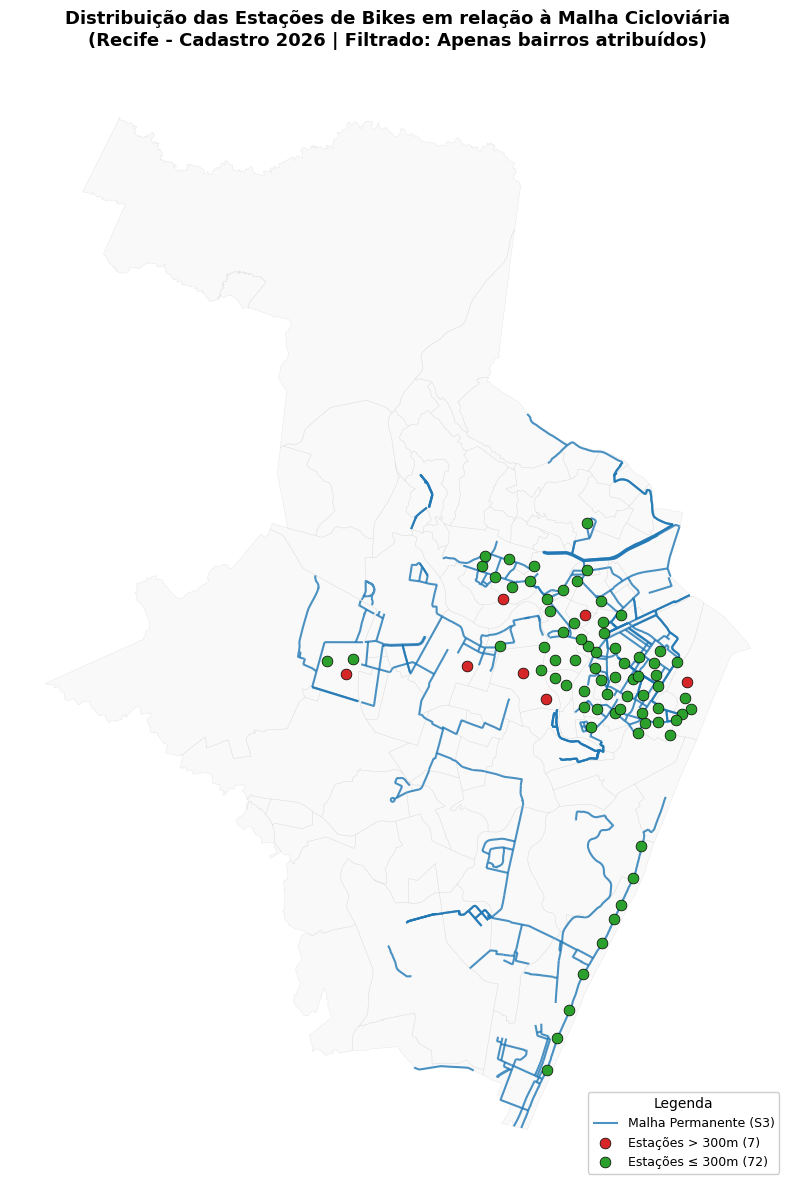


✅ Novo mapa salvo em: /content/drive/MyDrive/Backup_ETL4_Recife/processed/mapa_estacoes_corrigido_v2.png


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os

print("🗺️ Gerando mapa CORRIGIDO (excluindo estações sem bairro atribuído)...")

# 1. Carregar dados
caminho_estacoes = "/content/drive/MyDrive/Backup_ETL4_Recife/processed/estacoes_bikes_com_proximidade.geojson"
caminho_malha = "/content/drive/MyDrive/Backup_ETL3_Recife/processed/malha_cicloviaria_por_bairro.geojson"
caminho_bairros = "/content/drive/MyDrive/Backup_ETL3_Recife/raw/limites_bairros_raw.geojson"

gdf_estacoes = gpd.read_file(caminho_estacoes)
gdf_malha = gpd.read_file(caminho_malha)
gdf_bairros = gpd.read_file(caminho_bairros)

# Filtrar malha permanente
gdf_malha_permanente = gdf_malha[gdf_malha['Categoria'] == 'Permanente'].copy()

# 2. FILTRO DE QUALIDADE: Remover estações sem bairro atribuído (None/NaN)
gdf_estacoes_validas = gdf_estacoes[gdf_estacoes['Nome_Bairro_Oficial'].notna()].copy()

total_original = len(gdf_estacoes)
total_validas = len(gdf_estacoes_validas)
excluidas = total_original - total_validas

print(f"✅ Total original: {total_original}")
print(f"✅ Estações com bairro válido: {total_validas}")
print(f"⚠️ Estações excluídas da visualização (sem bairro atribuído): {excluidas}")

# Converter para WGS84 para plotagem correta
gdf_estacoes_validas_4326 = gdf_estacoes_validas.to_crs("EPSG:4326")
gdf_malha_permanente_4326 = gdf_malha_permanente.to_crs("EPSG:4326")
gdf_bairros_4326 = gdf_bairros.to_crs("EPSG:4326")

# Separar por proximidade
estacoes_perto = gdf_estacoes_validas_4326[gdf_estacoes_validas_4326['proximidade_300m'] == True]
estacoes_longe = gdf_estacoes_validas_4326[gdf_estacoes_validas_4326['proximidade_300m'] == False]

# 3. Plotar o mapa limpo
fig, ax = plt.subplots(figsize=(10, 12))

# Fundo de bairros
gdf_bairros_4326.plot(ax=ax, facecolor='#f5f5f5', edgecolor='#cccccc', linewidth=0.3, alpha=0.5)

# Malha permanente
gdf_malha_permanente_4326.plot(ax=ax, color='#1f77b4', linewidth=1.5, alpha=0.8, label='Malha Permanente (S3)')

# Estações
estacoes_longe.plot(ax=ax, color='#d62728', markersize=60, edgecolor='black', linewidth=0.5,
                    label=f'Estações > 300m ({len(estacoes_longe)})', zorder=5)
estacoes_perto.plot(ax=ax, color='#2ca02c', markersize=60, edgecolor='black', linewidth=0.5,
                    label=f'Estações ≤ 300m ({len(estacoes_perto)})', zorder=5)

plt.title("Distribuição das Estações de Bikes em relação à Malha Cicloviária\n(Recife - Cadastro 2026 | Filtrado: Apenas bairros atribuídos)",
          fontsize=13, fontweight='bold', pad=15)

ax.legend(loc='lower right', fontsize=9, framealpha=0.95, title="Legenda")
ax.set_axis_off()

plt.tight_layout()
caminho_mapa_corrigido = "/content/drive/MyDrive/Backup_ETL4_Recife/processed/mapa_estacoes_corrigido_v2.png"
plt.savefig(caminho_mapa_corrigido, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✅ Novo mapa salvo em: {caminho_mapa_corrigido}")